First 5 Rows
  College_ID   IQ  Prev_Sem_Result  CGPA  Academic_Performance  \
0    CLG0030  107             6.61  6.28                     8   
1    CLG0061   97             5.52  5.37                     8   
2    CLG0036  109             5.36  5.83                     9   
3    CLG0055  122             5.47  5.75                     6   
4    CLG0004   96             7.91  7.69                     7   

  Internship_Experience  Extra_Curricular_Score  Communication_Skills  \
0                    No                       8                     8   
1                    No                       7                     8   
2                    No                       3                     1   
3                   Yes                       1                     6   
4                    No                       8                    10   

   Projects_Completed Placement  
0                   4        No  
1                   0        No  
2                   1        No  
3              

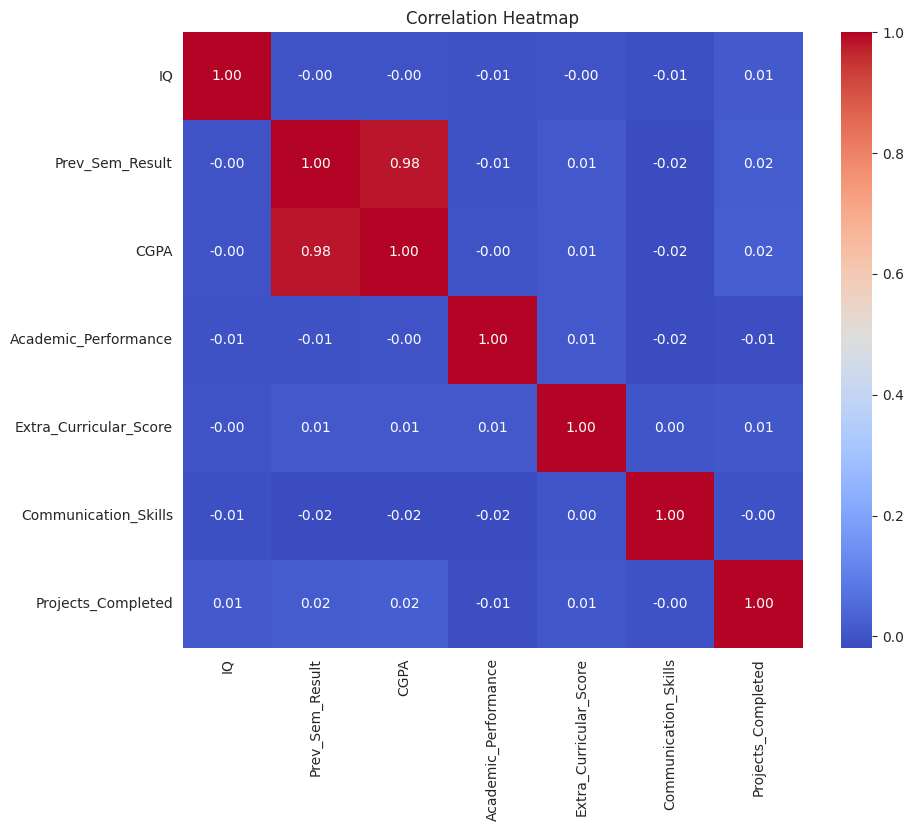

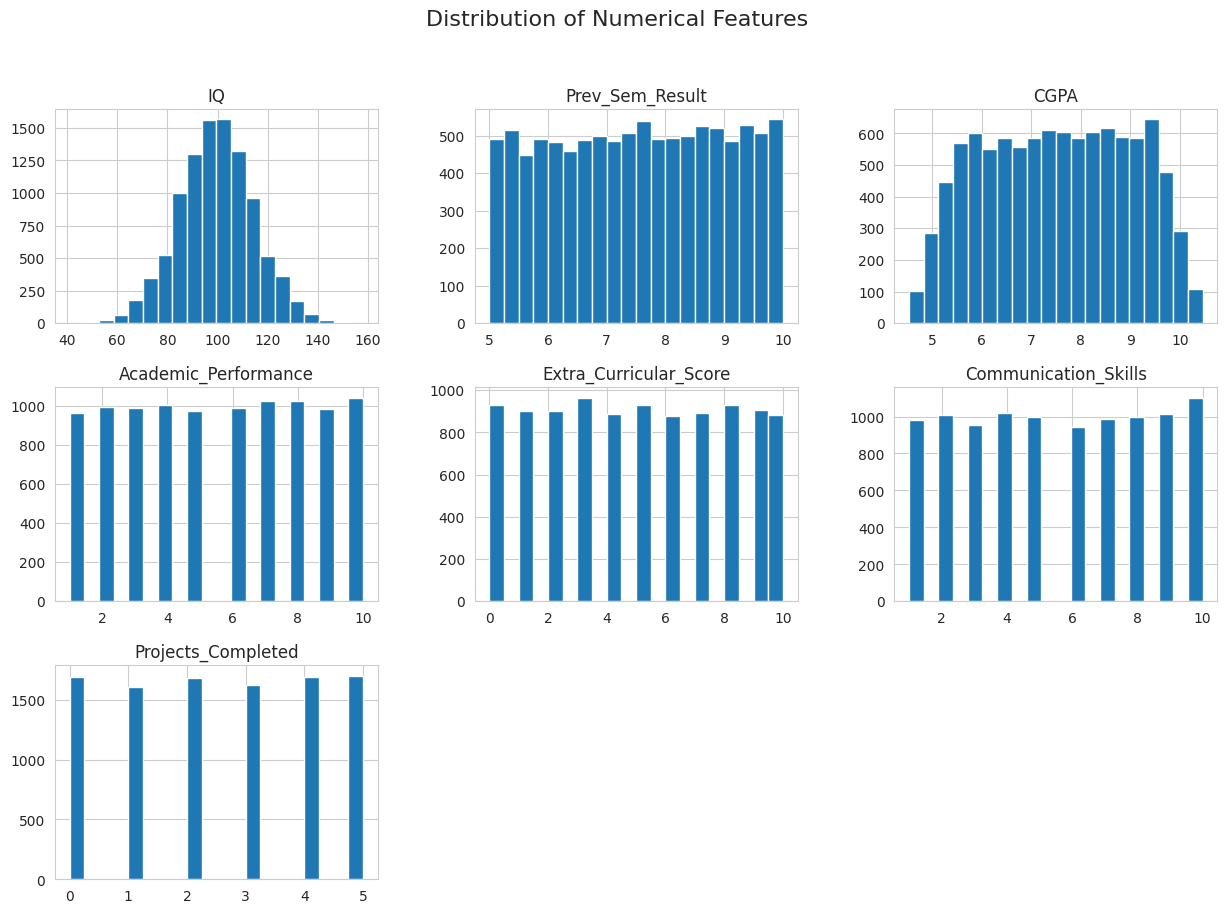

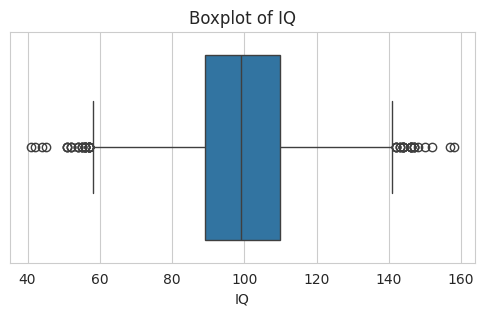

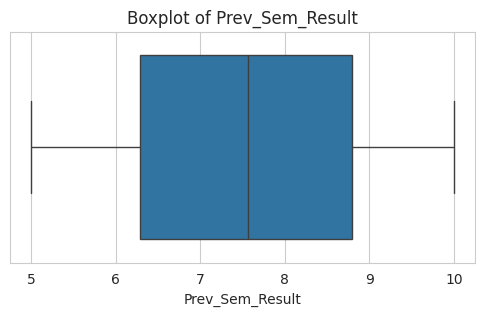

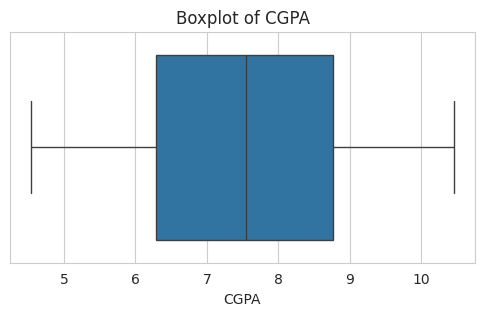

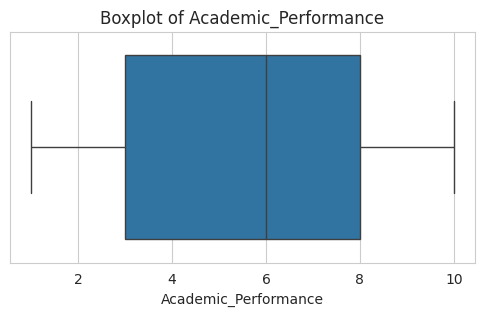

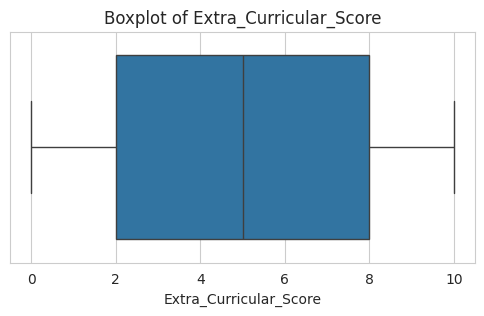

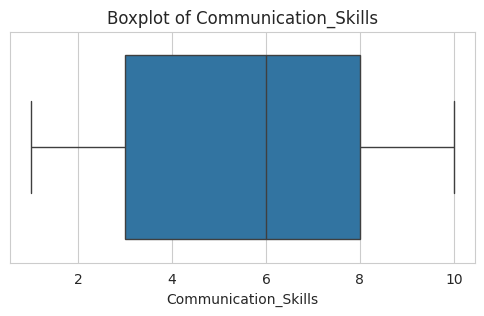

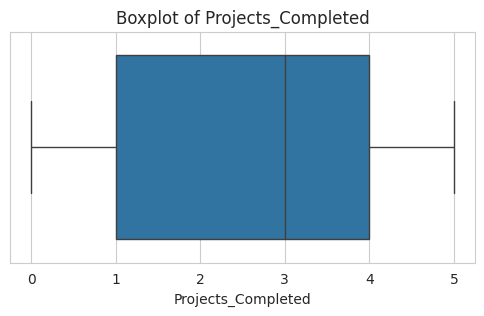

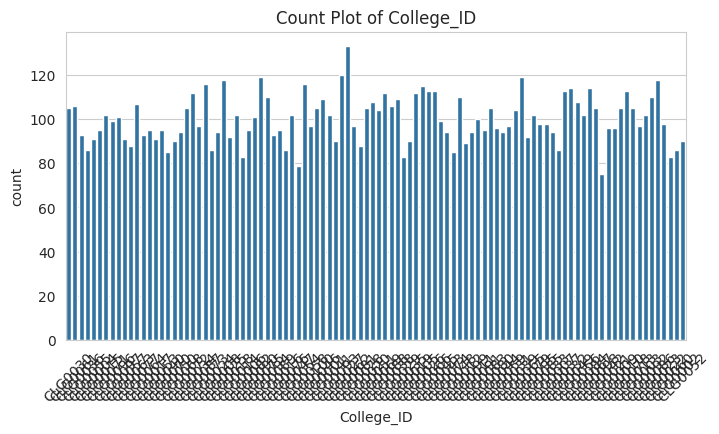

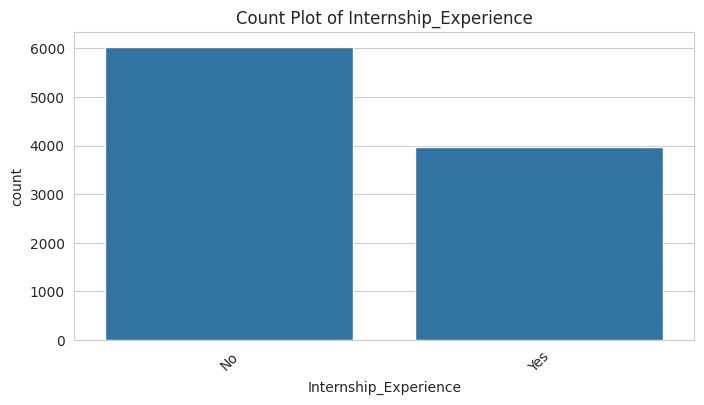

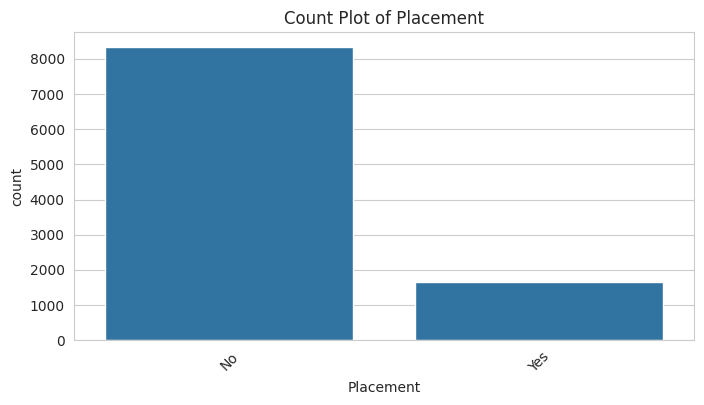

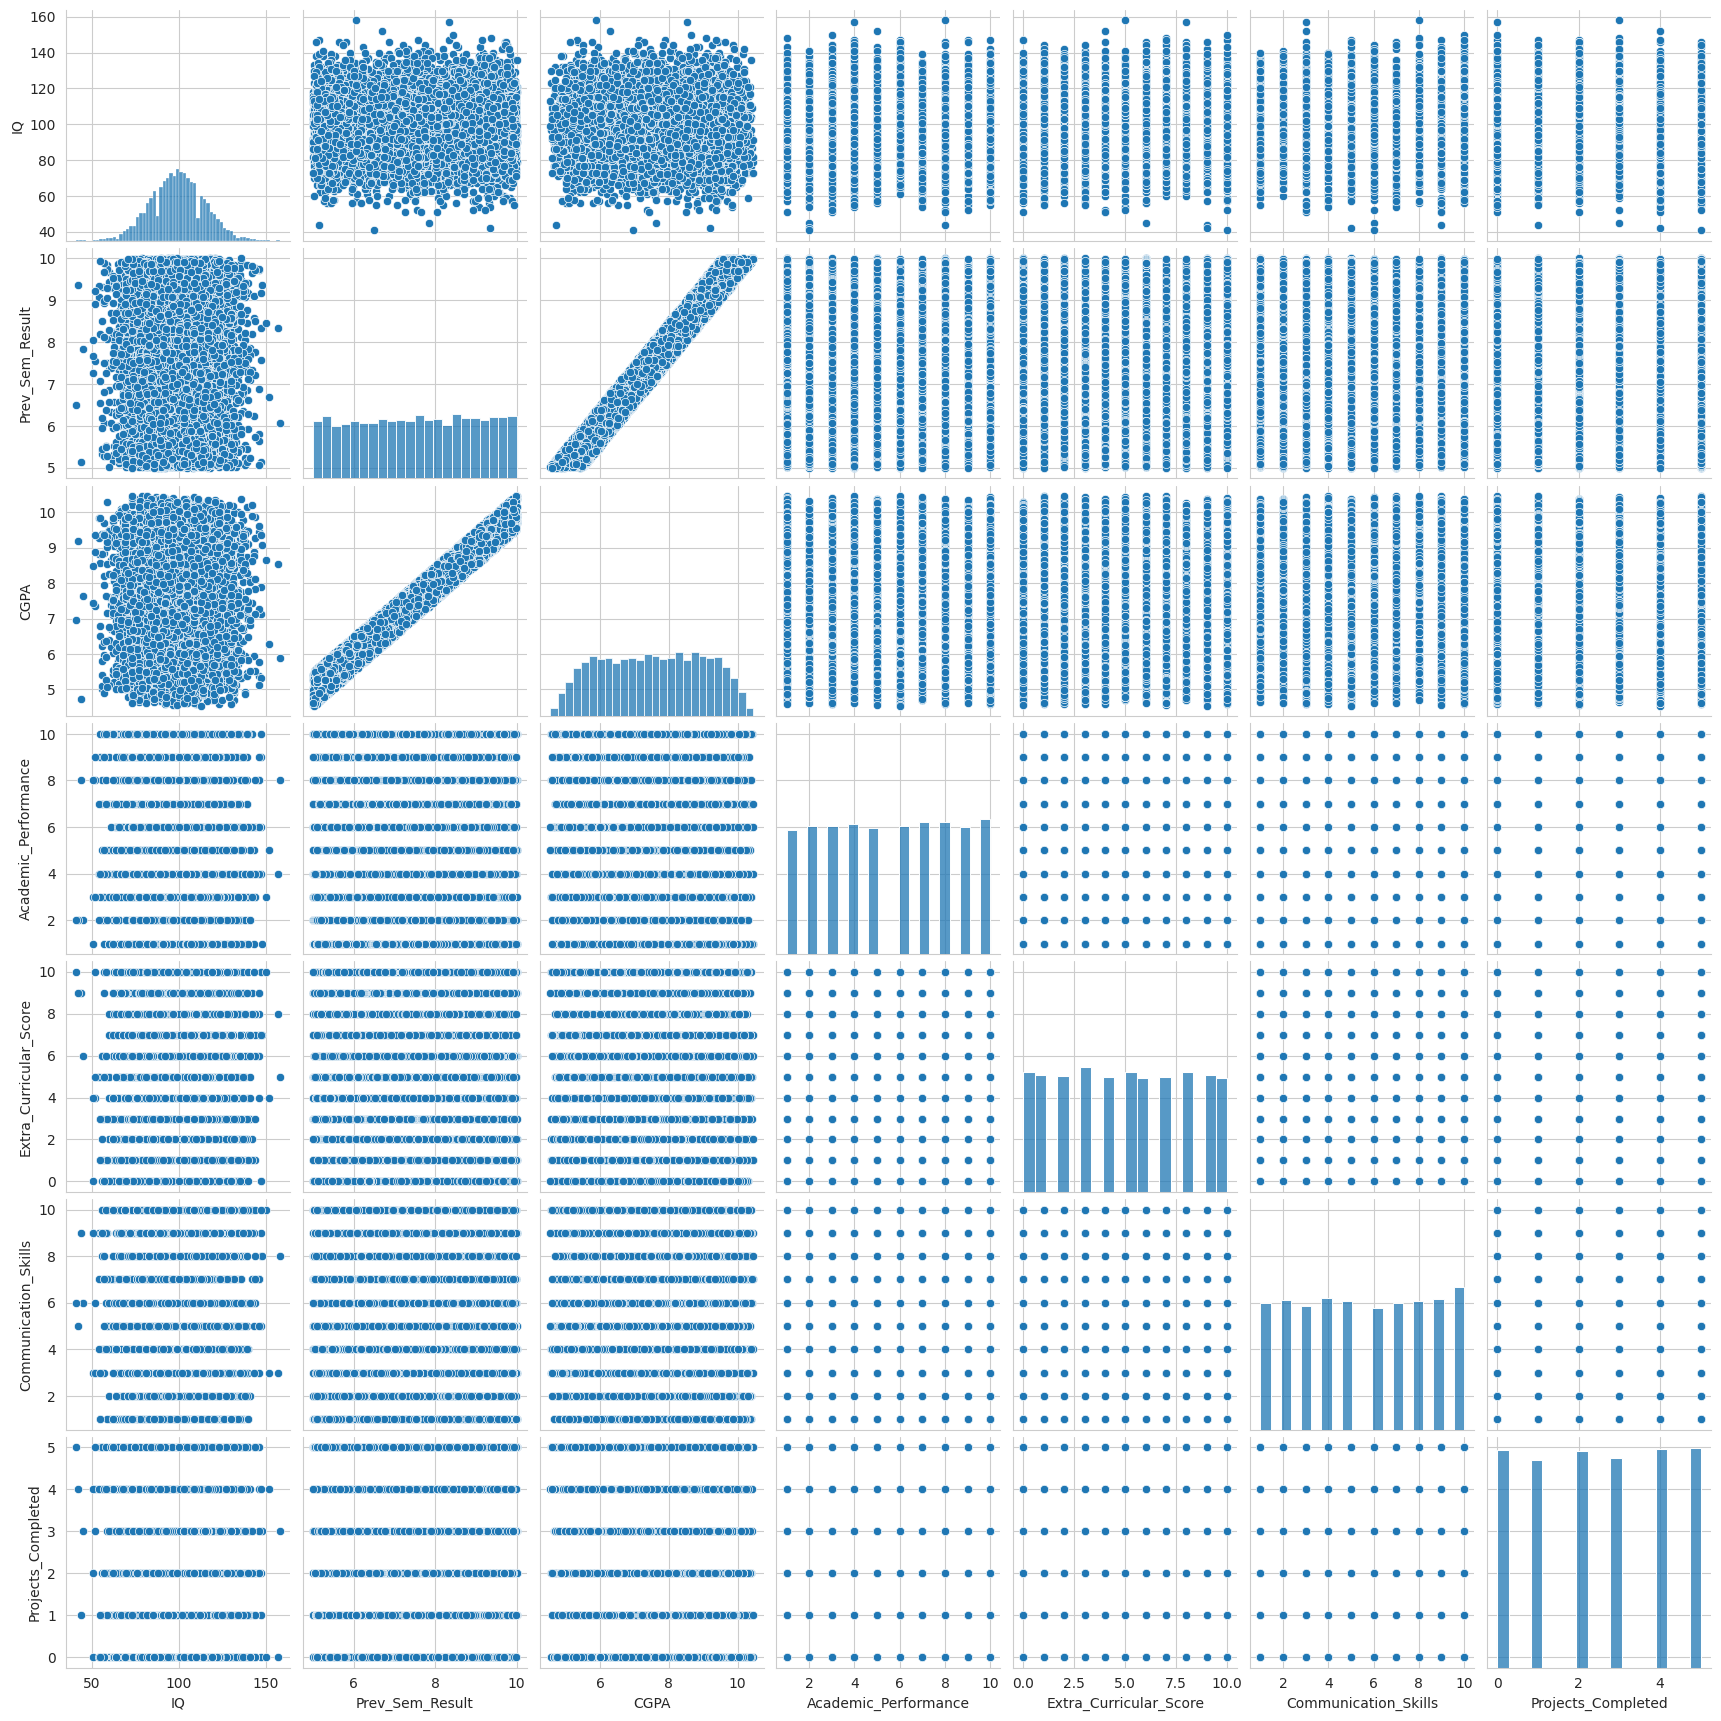

EDA Completed Successfully!


In [3]:
# ==========================
# Load Dataset & EDA
# ==========================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/sahilislam007/college-student-placement-factors-dataset/college_student_placement_dataset.csv")

# ==========================
# Basic Information
# ==========================

print("="*60)
print("First 5 Rows")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("Last 5 Rows")
print("="*60)
print(df.tail())

print("\n" + "="*60)
print("Dataset Shape")
print("="*60)
print(df.shape)

print("\n" + "="*60)
print("Column Names")
print("="*60)
print(df.columns.tolist())

print("\n" + "="*60)
print("Data Types")
print("="*60)
print(df.dtypes)

print("\n" + "="*60)
print("Dataset Information")
print("="*60)
df.info()

print("\n" + "="*60)
print("Missing Values")
print("="*60)
print(df.isnull().sum())

print("\n" + "="*60)
print("Duplicate Rows")
print("="*60)
print(df.duplicated().sum())

print("\n" + "="*60)
print("Statistical Summary")
print("="*60)
print(df.describe())

print("\n" + "="*60)
print("Categorical Summary")
print("="*60)
print(df.describe(include='object'))

# ==========================
# Unique Values
# ==========================

print("\n" + "="*60)
print("Unique Values")
print("="*60)

for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

# ==========================
# Value Counts
# ==========================

print("\nPlacement Distribution")
print(df["Placement"].value_counts())

print("\nInternship Experience Distribution")
print(df["Internship_Experience"].value_counts())

# ==========================
# Correlation Matrix
# ==========================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# ==========================
# Histograms
# ==========================

numeric_df.hist(figsize=(15,10), bins=20)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.show()

# ==========================
# Boxplots
# ==========================

for col in numeric_df.columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

# ==========================
# Count Plots
# ==========================

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=col)
    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=45)
    plt.show()

# ==========================
# Pairplot (Numerical Features)
# ==========================

sns.pairplot(numeric_df)
plt.show()

print("="*60)
print("EDA Completed Successfully!")
print("="*60)

In [4]:
# ==========================
# Data Preprocessing
# ==========================

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/sahilislam007/college-student-placement-factors-dataset/college_student_placement_dataset.csv")

# Remove Duplicate Rows
df = df.drop_duplicates()

# Check Missing Values
print("Missing Values:")
print(df.isnull().sum())

# Encode Categorical Columns
le = LabelEncoder()

categorical_cols = ['College_ID', 'Internship_Experience', 'Placement']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Features and Target
X = df.drop('Placement', axis=1)
y = df['Placement']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Display Results
print("\nPreprocessing Completed Successfully!")
print("Training Data Shape :", X_train.shape)
print("Testing Data Shape  :", X_test.shape)
print("Training Labels Shape :", y_train.shape)
print("Testing Labels Shape  :", y_test.shape)

Missing Values:
College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

Preprocessing Completed Successfully!
Training Data Shape : (8000, 9)
Testing Data Shape  : (2000, 9)
Training Labels Shape : (8000,)
Testing Labels Shape  : (2000,)


In [5]:
# ==========================
# Random Forest Classifier
# ==========================

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/sahilislam007/college-student-placement-factors-dataset/college_student_placement_dataset.csv")

# Remove Duplicate Rows
df = df.drop_duplicates()

# Encode Categorical Columns
le = LabelEncoder()

categorical_cols = ['College_ID', 'Internship_Experience', 'Placement']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Features and Target
X = df.drop('Placement', axis=1)
y = df['Placement']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create Random Forest Model
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Model
rf_classifier.fit(X_train, y_train)

# Predictions
y_pred = rf_classifier.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Random Forest Evaluation
Accuracy  : 0.9990
Precision : 1.0000
Recall    : 0.9940
F1 Score  : 0.9970

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1668
           1       1.00      0.99      1.00       332

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



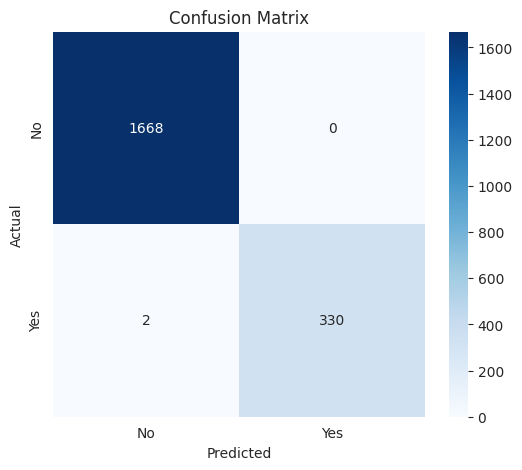

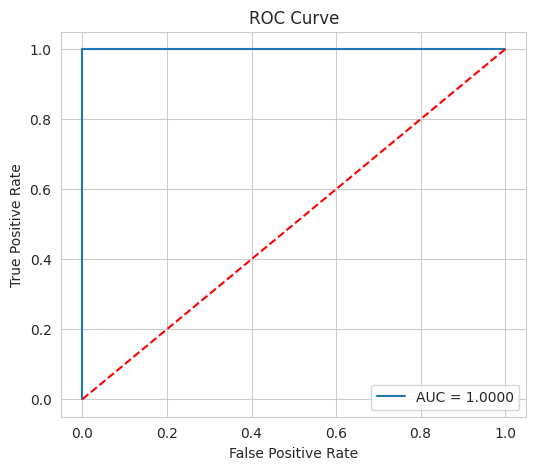


Feature Importance
                  Feature  Importance
7    Communication_Skills    0.264357
1                      IQ    0.239981
8      Projects_Completed    0.208448
3                    CGPA    0.163172
2         Prev_Sem_Result    0.102943
0              College_ID    0.009543
6  Extra_Curricular_Score    0.005782
4    Academic_Performance    0.004552
5   Internship_Experience    0.001223


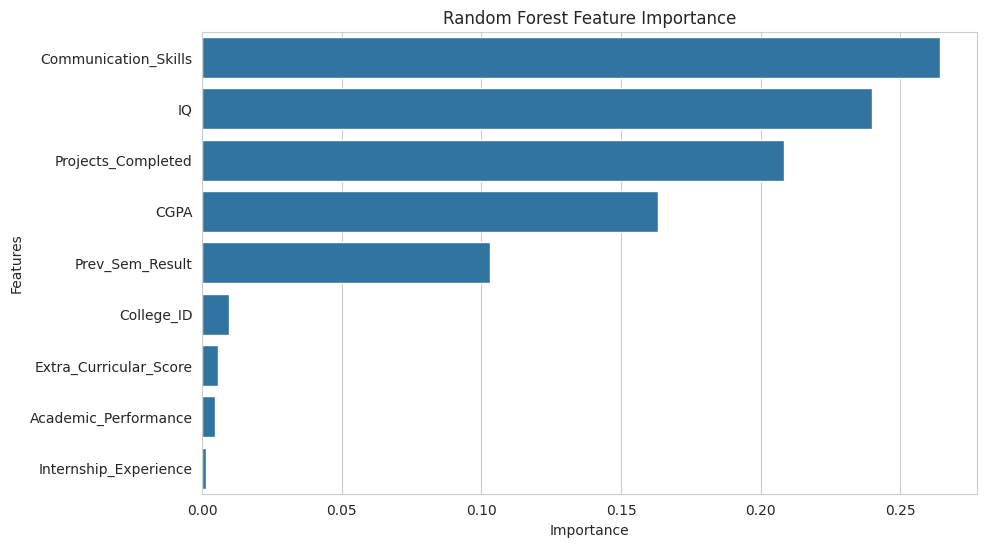

In [6]:
# ==========================
# Evaluation Metrics & Visualization
# ==========================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Predictions
y_pred = rf_classifier.predict(X_test)

# ==========================
# Evaluation Metrics
# ==========================

print("="*50)
print("Random Forest Evaluation")
print("="*50)

print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred):.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# ==========================
# Confusion Matrix
# ==========================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'],
            yticklabels=['No','Yes'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ==========================
# ROC Curve
# ==========================

y_prob = rf_classifier.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# ==========================
# Feature Importance
# ==========================

importance = rf_classifier.feature_importances_
feature_names = X.columns

importance_df = (
    __import__("pandas")
    .DataFrame({"Feature": feature_names, "Importance": importance})
    .sort_values(by="Importance", ascending=False)
)

print("\nFeature Importance")
print(importance_df)

plt.figure(figsize=(10,6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()